# Triagem de hipotireoidismo a partir de exames de laboratório

Projeto de Parceria EBAC e Semantix. Trabalho com a base Hypothyroid (3.772 pacientes), do UCI Machine Learning Repository. O notebook segue o fluxo completo: problema, fonte dos dados, limpeza, análise exploratória, modelagem, avaliação e uma recomendação para quem usaria o resultado.

Uma regra que segui o tempo todo: o treino e o teste são separados antes de qualquer imputação, padronização ou encoding. Essas etapas ficam dentro de pipelines, então só aprendem com o treino (e, na validação cruzada, só com o treino de cada fold).

Para rodar: `pip install -r requirements.txt` na raiz do repositório e executar este notebook de cima para baixo. O caminho dos dados e a semente aleatória (42) já estão fixados.

In [1]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (confusion_matrix, precision_score, recall_score, f1_score, fbeta_score,
                             roc_auc_score, average_precision_score, precision_recall_curve, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 100
SEED = 42

# 1. Problema, fonte dos dados e definição do alvo

**O problema.** Um laboratório ou uma clínica recebe todos os dias resultados de exames de tireoide e precisa decidir quais casos vão para confirmação com o endocrinologista. Hipotireoidismo é a produção insuficiente de hormônios pela tireoide. É uma condição tratável, e o risco está em não identificá-la. Revisar todos os pacientes consome tempo do especialista, e deixar passar um caso deixa uma pessoa sem tratamento.

**Por que dados e Machine Learning ajudam.** Os resultados chegam em volume e combinam vários sinais ao mesmo tempo: TSH, hormônios T3, TT4 e FTI, uso de medicação e exames que faltam em parte dos pacientes. Um modelo transforma tudo isso em uma probabilidade por paciente, e a equipe escolhe o ponto de corte conforme sua capacidade de revisão. O projeto também mostra um limite dessa abordagem: uma regra simples chega perto do modelo (seção 9), e isso pesa na recomendação final.

**Fonte dos dados.** UCI Machine Learning Repository, base Thyroid Disease, arquivo `hypothyroid` (registros do Garavan Institute, Sydney, doados por Ross Quinlan). É uma fonte pública, sem identificação pessoal dos pacientes. O próprio repositório avisa que Quinlan suspeita que essa base possa ter sido corrompida desde que chegou ao UCI, o que entra nas limitações. O arquivo usado aqui, `data/hypothyroid.csv`, tem 3.772 linhas e 30 colunas e foi o fornecido pelo curso.

**Tarefa de ML.** Classificação binária supervisionada.

**Variável-alvo.** `alvo`, igual a 1 quando o paciente tem hipotireoidismo e 0 quando não tem. A base traz esse dado em `binaryClass` com as letras P e N, e a leitura natural seria P = positivo = doente. Antes de aceitar isso comparei as medianas dos exames por letra (célula abaixo).

In [2]:
bruto = pd.read_csv('../data/hypothyroid.csv')
print("Formato:", bruto.shape)
print("Células com '?':", int((bruto == '?').sum().sum()))
print("\nColunas com '?' (contagem):")
q = (bruto == '?').sum()
print(q[q > 0].to_dict())
print("\nBalanceamento do rotulo original (binaryClass):")
print(bruto['binaryClass'].value_counts().to_string())

Formato: (3772, 30)
Células com '?': 6064

Colunas com '?' (contagem):
{'age': 1, 'sex': 150, 'TSH': 369, 'T3': 769, 'TT4': 231, 'T4U': 387, 'FTI': 385, 'TBG': 3772}

Balanceamento do rotulo original (binaryClass):
binaryClass
P    3481
N     291


Os pacientes marcados com N têm TSH mediano de 12,0 contra 1,2 dos marcados com P, e TT4 e FTI bem mais baixos. TSH alto com hormônio tireoidiano baixo é justamente o quadro do hipotireoidismo, então **N é o paciente doente e P é o paciente sem a doença**. O rótulo vem invertido em relação ao que o nome sugere. Se eu tivesse usado `binaryClass` direto como "positivo", o recall e a precisão do modelo estariam medindo a classe errada. Por isso criei o alvo de forma explícita (N vira 1). São 291 casos de hipotireoidismo, 7,7% da base.

In [3]:
df = pd.read_csv('../data/hypothyroid.csv', na_values='?')   # '?' vira NaN de verdade

# qual das letras do rotulo representa o paciente com hipotireoidismo?
hormônios = ['TSH', 'TT4', 'T3', 'FTI']
print(df.groupby('binaryClass')[hormônios].median().round(2))

# alvo definido de forma explicita: 1 = hipotireoidismo
df['alvo'] = (df['binaryClass'] == 'N').astype(int)
print("\nPacientes com hipotireoidismo (alvo = 1):", df['alvo'].sum(), "| proporção:", round(df['alvo'].mean(), 4))

              TSH    TT4   T3    FTI
binaryClass                         
N            12.0   76.5  1.5   77.5
P             1.2  105.0  2.0  108.0

Pacientes com hipotireoidismo (alvo = 1): 291 | proporção: 0.0771


# 2. Limpeza dos dados

Quatro problemas apareceram na inspeção:

1. Uma idade de 455 anos, claramente erro de digitação. Troquei por ausente (o valor será imputado depois, só com o treino).
2. A coluna `TBG` está 100% vazia e `TBG measured` vale `f` em todas as linhas. Não carregam informação nenhuma, então saíram.
3. 61 linhas duplicadas, todas da classe sem hipotireoidismo. Removi antes do split. Se ficassem, a mesma linha poderia cair no treino e no teste e inflar a avaliação.
4. As colunas `t`/`f` viraram 1/0.

Os `?` já foram convertidos em ausente na leitura (`na_values='?'`). Se não fosse isso, colunas como TSH e TT4 seriam lidas como texto.

In [4]:
# 1) idade impossível
print("Idades acima de 120 anos:")
print(df.loc[df['age'] > 120, ['age', 'sex', 'TSH', 'binaryClass']])
df.loc[df['age'] > 120, 'age'] = np.nan

# 2) colunas sem informação
print("\nTBG preenchido em:", int(df['TBG'].notna().sum()), "linhas | 'TBG measured' valores:", df['TBG measured'].unique())
df = df.drop(columns=['TBG', 'TBG measured'])

# 3) linhas duplicadas (removidas antes do split, para a mesma linha não cair nos dois lados)
dup = df.duplicated().sum()
print("\nLinhas duplicadas:", dup, "| por classe:", df[df.duplicated()]['alvo'].value_counts().to_dict())
df = df.drop_duplicates().reset_index(drop=True)

# 4) t/f vira 1/0
bin_cols = [c for c in df.columns if set(df[c].dropna().unique()) <= {'t', 'f'}]
for c in bin_cols:
    df[c] = df[c].map({'t': 1, 'f': 0})
print("\nColunas t/f convertidas:", len(bin_cols))
print("Formato após a limpeza:", df.shape, "| prevalencia:", round(df['alvo'].mean(), 4))
print("\nTipos:")
print(df.dtypes.value_counts().to_string())

Idades acima de 120 anos:
        age sex  TSH binaryClass
1364  455.0   F  1.1           P

TBG preenchido em: 0 linhas | 'TBG measured' valores: <StringArray>
['f']
Length: 1, dtype: str

Linhas duplicadas: 61 | por classe: {0: 61}

Colunas t/f convertidas: 19
Formato após a limpeza: (3711, 29) | prevalencia: 0.0784

Tipos:
int64      20
float64     6
str         3


# 3. Análise exploratória

Fiz sete análises: distribuição do alvo e ausentes, medidas resumo e assimetria, comparação dos exames por classe com teste estatístico, correlação, variáveis binárias e categóricas contra o alvo, os indicadores de exame medido e a relação entre TSH alto e tratamento.

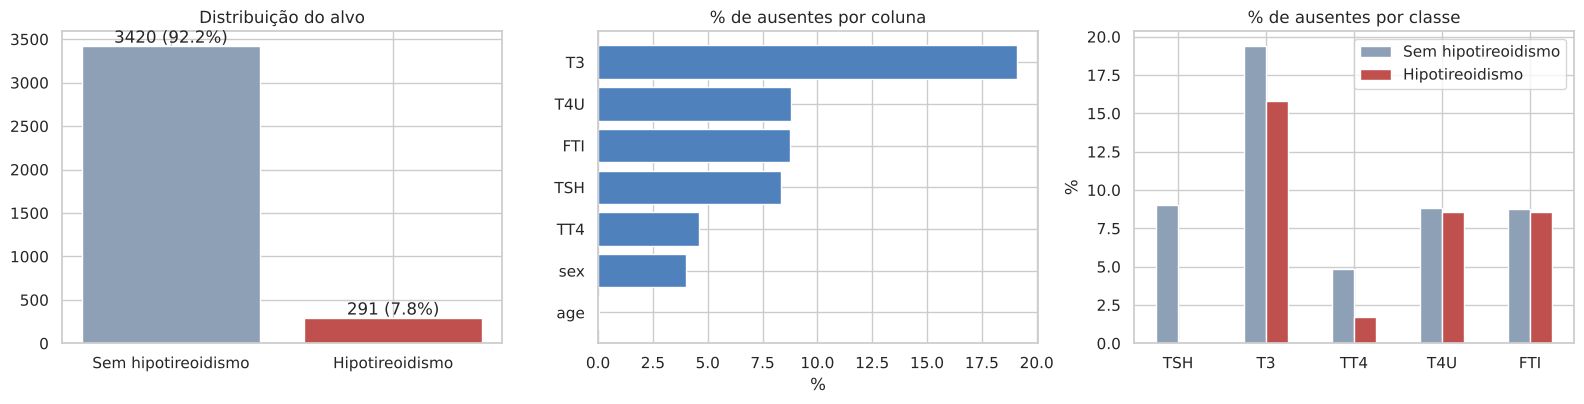

     Sem hipotireoidismo  Hipotireoidismo
TSH                  9.0              0.0
T3                  19.4             15.8
TT4                  4.9              1.7
T4U                  8.8              8.6
FTI                  8.8              8.6


In [5]:
# EDA 1: alvo e dados ausentes
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
cont = df['alvo'].value_counts().sort_index()
ax[0].bar(['Sem hipotireoidismo', 'Hipotireoidismo'], cont.values, color=['#8da0b6', '#c0504d'])
for i, v in enumerate(cont.values):
    ax[0].text(i, v + 40, f"{v} ({v/len(df):.1%})", ha='center')
ax[0].set_title('Distribuição do alvo')

nulos = df[['age', 'sex', 'TSH', 'T3', 'TT4', 'T4U', 'FTI']].isna().mean().sort_values()
ax[1].barh(nulos.index, nulos.values * 100, color='#4f81bd')
ax[1].set_title('% de ausentes por coluna')
ax[1].set_xlabel('%')

por_classe = df[['TSH', 'T3', 'TT4', 'T4U', 'FTI']].isna().groupby(df['alvo']).mean().T * 100
por_classe.columns = ['Sem hipotireoidismo', 'Hipotireoidismo']
por_classe.plot.bar(ax=ax[2], color=['#8da0b6', '#c0504d'], rot=0)
ax[2].set_title('% de ausentes por classe')
ax[2].set_ylabel('%')
plt.tight_layout(); plt.show()
print(por_classe.round(1))

      count    mean     50%    std   min     max  assimetria
age  3709.0   51.75   54.00  19.01  1.00   94.00       -0.22
TSH  3402.0    5.09    1.40  24.52  0.00  530.00       13.88
T3   3002.0    2.01    2.00   0.83  0.05   10.60        1.73
TT4  3540.0  108.33  103.00  35.61  2.00  430.00        1.27
T4U  3384.0    0.99    0.98   0.20  0.25    2.32        1.23
FTI  3386.0  110.48  107.00  33.09  2.00  395.00        1.35


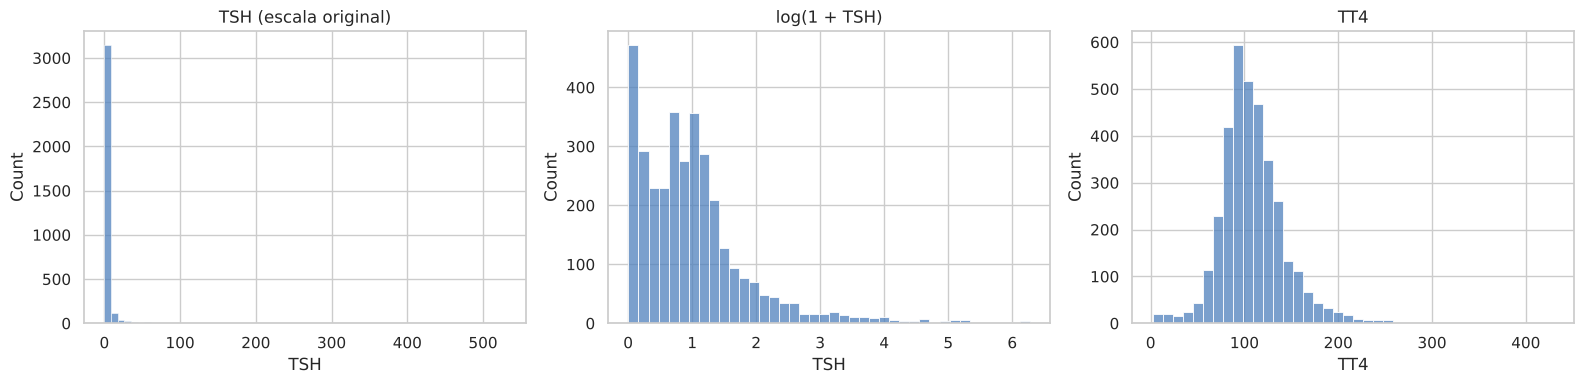

In [6]:
# EDA 2: medidas resumo e assimetria dos exames
num = ['age', 'TSH', 'T3', 'TT4', 'T4U', 'FTI']
resumo = df[num].describe().T[['count', 'mean', '50%', 'std', 'min', 'max']]
resumo['assimetria'] = df[num].skew()
print(resumo.round(2))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df['TSH'], bins=60, ax=ax[0], color='#4f81bd'); ax[0].set_title('TSH (escala original)')
sns.histplot(np.log1p(df['TSH']), bins=40, ax=ax[1], color='#4f81bd'); ax[1].set_title('log(1 + TSH)')
sns.histplot(df['TT4'], bins=40, ax=ax[2], color='#4f81bd'); ax[2].set_title('TT4')
plt.tight_layout(); plt.show()

          mediana_hipo  mediana_sem  efeito  p_valor
variável                                            
age              55.00        54.00  0.0001   0.9984
TSH              12.00         1.20  0.9725   0.0000
T3                1.50         2.00 -0.4015   0.0000
TT4              76.50       105.00 -0.5777   0.0000
T4U               1.01         0.97  0.1037   0.0049
FTI              77.50       108.50 -0.6381   0.0000


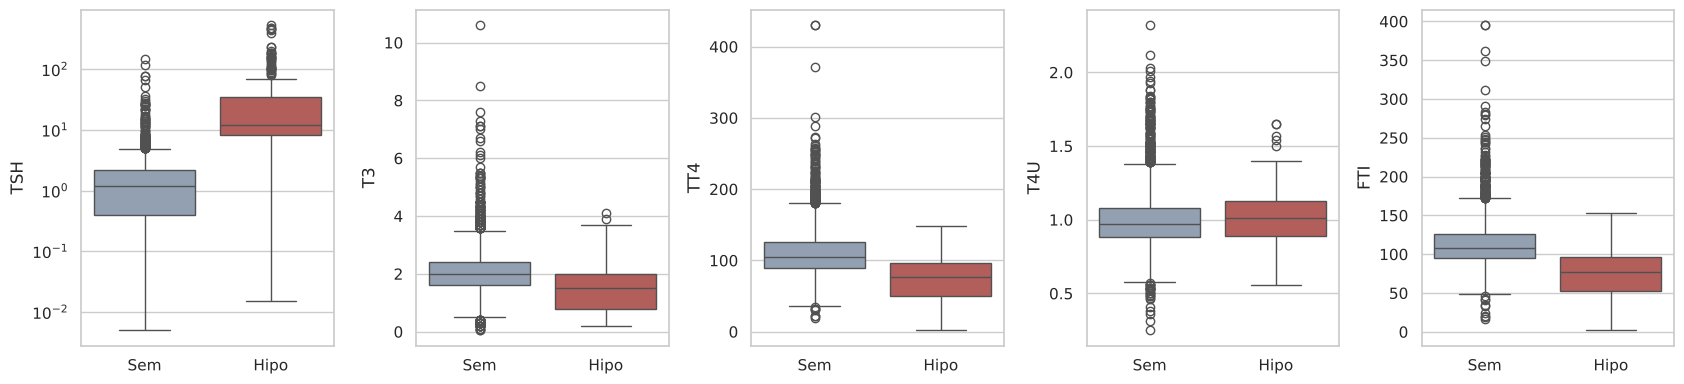

In [7]:
# EDA 3: exames por classe e teste estatístico (Mann-Whitney, sem supor normalidade)
linhas = []
for c in ['age', 'TSH', 'T3', 'TT4', 'T4U', 'FTI']:
    a = df.loc[df['alvo'] == 1, c].dropna(); b = df.loc[df['alvo'] == 0, c].dropna()
    u, p = stats.mannwhitneyu(a, b)
    efeito = 1 - 2 * u / (len(a) * len(b))          # correlação rank-biserial
    linhas.append([c, a.median(), b.median(), -efeito, p])
tab = pd.DataFrame(linhas, columns=['variável', 'mediana_hipo', 'mediana_sem', 'efeito', 'p_valor']).set_index('variável')
print(tab.round(4))

fig, ax = plt.subplots(1, 5, figsize=(17, 4))
for a_, c in zip(ax, ['TSH', 'T3', 'TT4', 'T4U', 'FTI']):
    sns.boxplot(data=df, x='alvo', y=c, ax=a_, palette=['#8da0b6', '#c0504d'])
    a_.set_xticklabels(['Sem', 'Hipo']); a_.set_xlabel('')
    if c == 'TSH': a_.set_yscale('log')
plt.tight_layout(); plt.show()

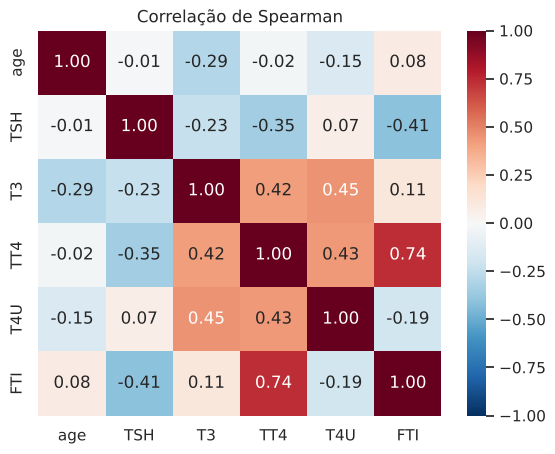

Correlação entre FTI e TT4/T4U: 1.0


In [8]:
# EDA 4: correlação de Spearman entre os exames
corr = df[['age', 'TSH', 'T3', 'TT4', 'T4U', 'FTI']].corr(method='spearman')
plt.figure(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1)
plt.title('Correlação de Spearman'); plt.show()

# o FTI parece ser TT4 corrigido pela T4U: conferindo
ok = df[['TT4', 'T4U', 'FTI']].dropna()
print("Correlação entre FTI e TT4/T4U:", round(np.corrcoef(ok['FTI'], ok['TT4'] / ok['T4U'])[0, 1], 3))

In [9]:
# EDA 5: variáveis categóricas e binárias contra o alvo (qui-quadrado / Fisher)
cats = ['on thyroxine', 'on antithyroid medication', 'sick', 'pregnant', 'thyroid surgery', 'I131 treatment',
        'query hypothyroid', 'query hyperthyroid', 'lithium', 'goitre', 'tumor', 'hypopituitary', 'psych']
res = []
for c in cats:
    t = pd.crosstab(df[c], df['alvo'])
    if t.shape == (2, 2):
        p = stats.fisher_exact(t)[1]
        taxa1 = df.loc[df[c] == 1, 'alvo'].mean()
        res.append([c, int((df[c] == 1).sum()), taxa1, df.loc[df[c] == 0, 'alvo'].mean(), p])
res = pd.DataFrame(res, columns=['variável', 'n_com_1', 'taxa_hipo_se_1', 'taxa_hipo_se_0', 'p_valor']).set_index('variável')
print(res.round(4).sort_values('p_valor'))

print("\nPor sexo:")
print(df.groupby(df['sex'].fillna('ausente'))['alvo'].agg(['count', 'mean']).round(3))
print("Qui-quadrado sexo (F x M): p =", round(stats.chi2_contingency(pd.crosstab(df['sex'], df['alvo']))[1], 4))
print("\nPor origem do encaminhamento:")
print(df.groupby('referral source')['alvo'].agg(['count', 'mean']).round(3))
print("Qui-quadrado origem: p =", round(stats.chi2_contingency(pd.crosstab(df['referral source'], df['alvo']))[1], 4))

                           n_com_1  taxa_hipo_se_1  taxa_hipo_se_0  p_valor
variável                                                                   
on thyroxine                   464          0.0194          0.0868   0.0000
query hypothyroid              234          0.1667          0.0725   0.0000
pregnant                        53          0.0000          0.0796   0.0199
psych                          184          0.0435          0.0802   0.0893
goitre                          34          0.0000          0.0791   0.1073
on antithyroid medication       42          0.0238          0.0790   0.2533
thyroid surgery                 53          0.0377          0.0790   0.4351
query hyperthyroid             234          0.0641          0.0794   0.4527
I131 treatment                  59          0.0847          0.0783   0.8060
tumor                           96          0.0833          0.0783   0.8466
sick                           147          0.0748          0.0786   1.0000
lithium     

In [10]:
# EDA 6: a armadilha dos flags "measured" (o exame foi pedido ou não?)
medidos = [c for c in df.columns if c.endswith('measured')]
print(df.groupby('alvo')[medidos].mean().round(3).T.rename(columns={0: 'sem hipo', 1: 'hipo'}))
print("\nPacientes sem TSH medido:", int((df['TSH measured'] == 0).sum()),
      "| com hipotireoidismo entre eles:", int(df.loc[df['TSH measured'] == 0, 'alvo'].sum()))
print("Pacientes sem nenhum dos 4 hormônios (TSH, T3, TT4, FTI) medidos:",
      int((df[['TSH measured', 'T3 measured', 'TT4 measured', 'FTI measured']].sum(axis=1) == 0).sum()))

alvo          sem hipo   hipo
TSH measured     0.910  1.000
T3 measured      0.806  0.842
TT4 measured     0.951  0.983
T4U measured     0.912  0.914
FTI measured     0.912  0.914

Pacientes sem TSH medido: 309 | com hipotireoidismo entre eles: 0
Pacientes sem nenhum dos 4 hormônios (TSH, T3, TT4, FTI) medidos: 119


                       pacientes  com_hipo  taxa_hipo
TSH_alto tratado                                     
TSH <= 6 em tiroxina         371         0      0.000
         sem tiroxina       2665         2      0.001
TSH > 6  em tiroxina          63         9      0.143
         sem tiroxina        303       280      0.924


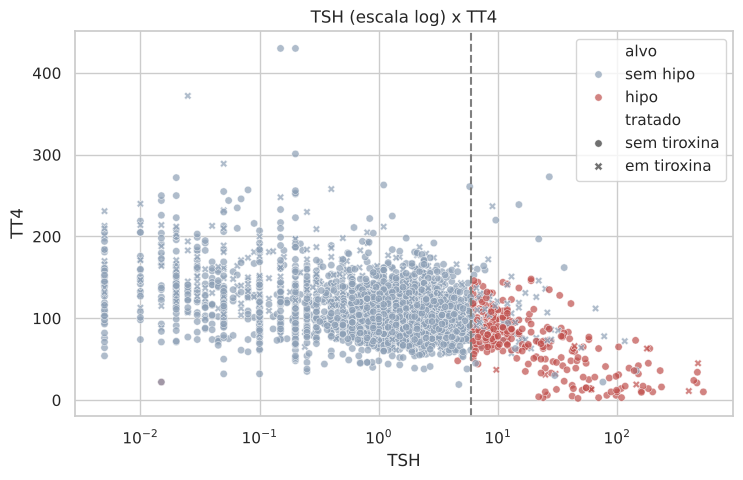

In [11]:
# EDA 7: TSH alto e tratamento com tiroxina
d = df[df['TSH'].notna()].copy()
d['TSH_alto'] = np.where(d['TSH'] > 6, 'TSH > 6', 'TSH <= 6')
d['tratado'] = np.where(d['on thyroxine'] == 1, 'em tiroxina', 'sem tiroxina')
t = d.groupby(['TSH_alto', 'tratado'])['alvo'].agg(['count', 'sum', 'mean'])
t.columns = ['pacientes', 'com_hipo', 'taxa_hipo']
print(t.round(3).to_string())

plt.figure(figsize=(8.5, 5))
sns.scatterplot(data=d, x='TSH', y='TT4', hue=d['alvo'].map({0: 'sem hipo', 1: 'hipo'}), style='tratado',
                palette=['#8da0b6', '#c0504d'], alpha=0.7, s=28)
plt.xscale('log'); plt.axvline(6, ls='--', color='gray')
plt.title('TSH (escala log) x TT4'); plt.show()

## Principais achados da exploração

O alvo é desbalanceado (7,8% de casos depois de remover as duplicatas). Isso muda a escolha da métrica: um modelo que diz "sem hipotireoidismo" para todo mundo acerta 92% e não encontra ninguém.

Os ausentes não são aleatórios. O TSH está ausente em 9,0% dos pacientes sem a doença e em 0,0% dos doentes. Em outras palavras, nenhum dos 309 pacientes sem TSH medido tem hipotireoidismo. Isso parece ser consequência de como a base foi rotulada (o diagnóstico depende do TSH), e não uma característica dos pacientes. Os indicadores "measured" carregam, portanto, a história de quem pediu exame, não a biologia.

O TSH tem assimetria de 13,9 (média 5,1, mediana 1,4, máximo 530). Na escala log fica razoável, e foi o que usei na regressão logística. Dos exames, o TSH é o que mais separa as classes: tamanho de efeito de 0,97 no teste de Mann-Whitney (1 seria separação perfeita), seguido por FTI (0,64), TT4 (0,58) e T3 (0,40). Idade não diferencia as classes (p = 0,998).

O FTI tem correlação de 1,00 com TT4/T4U, ou seja, ele é calculado a partir dessas duas medidas. Na correlação de Spearman o TT4 e o FTI aparecem juntos (0,74). Para árvores isso não atrapalha, mas na regressão logística os coeficientes dos dois ficam instáveis.

Tomar tiroxina muda o jogo. Entre quem toma, 1,9% está rotulado como hipotireoidismo, contra 8,7% entre quem não toma (p < 0,001). A célula 7 mostra o motivo: com TSH acima de 6 e sem tiroxina, 280 de 303 pacientes (92,4%) são casos. Com TSH acima de 6 mas já em tiroxina, só 9 de 63 (14,3%). Parece que o rótulo marca quem tem a doença sem tratamento. Com TSH até 6 há apenas 2 casos em 3.036 pacientes.

Nas outras variáveis: mulheres 8,9% e homens 5,7% (p = 0,001), o encaminhamento pela origem SVHC tem 2,8% e a SVI 9,4% (p = 0,002), e pacientes com a pergunta "query hypothyroid" marcada têm 16,7% contra 7,3%. Gravidez (0 de 53) e bócio (0 de 34) não têm nenhum caso, mas são grupos pequenos e só a gravidez passa no teste (p = 0,02).

# 4. Preparação para a modelagem

Separei 80% para treino e 20% para teste, estratificado pelo alvo (233 casos no treino, 58 no teste), antes de qualquer transformação. O pré-processamento fica num `ColumnTransformer` dentro do pipeline:

- TSH: mediana do treino para os ausentes, log(1 + x) e padronização.
- Outros exames (idade, T3, TT4, T4U, FTI): mediana e padronização.
- Variáveis clínicas t/f: já são 0 e 1, passam direto.
- Sexo e origem do encaminhamento: ausente vira uma categoria própria e depois one-hot.

Deixei os indicadores "measured" de fora do modelo principal pelo motivo explicado acima, e testo na próxima seção se isso muda alguma coisa.

In [12]:
# colunas de cada tipo
exames = ['age', 'TSH', 'T3', 'TT4', 'T4U', 'FTI']
flags_clin = ['on thyroxine', 'query on thyroxine', 'on antithyroid medication', 'sick', 'pregnant', 'thyroid surgery',
              'I131 treatment', 'query hypothyroid', 'query hyperthyroid', 'lithium', 'goitre', 'tumor', 'hypopituitary', 'psych']
categ = ['sex', 'referral source']
medidos = ['TSH measured', 'T3 measured', 'TT4 measured', 'T4U measured', 'FTI measured']

X = df[exames + flags_clin + categ + medidos]
y = df['alvo']

# split ANTES de qualquer imputação, escala ou encoding
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print("Treino:", X_tr.shape, "| casos positivos:", int(y_tr.sum()), f"({y_tr.mean():.1%})")
print("Teste: ", X_te.shape, "| casos positivos:", int(y_te.sum()), f"({y_te.mean():.1%})")

def montar_prep(usar_medidos=False):
    transf = [
        ('tsh', Pipeline([('imp', SimpleImputer(strategy='median')),
                          ('log', FunctionTransformer(np.log1p)),
                          ('esc', StandardScaler())]), ['TSH']),
        ('exames', Pipeline([('imp', SimpleImputer(strategy='median')),
                             ('esc', StandardScaler())]), ['age', 'T3', 'TT4', 'T4U', 'FTI']),
        ('flags', 'passthrough', flags_clin + (medidos if usar_medidos else [])),
        ('cat', Pipeline([('imp', SimpleImputer(strategy='constant', fill_value='ausente')),
                          ('ohe', OneHotEncoder(handle_unknown='ignore'))]), categ),
    ]
    return ColumnTransformer(transf)

# conferindo que o split manteve a proporção e que as imputações usam só o treino
print("\nMediana do TSH usada na imputação (só treino):", round(X_tr['TSH'].median(), 2))
print("Mediana do TSH no teste (não usada):", round(X_te['TSH'].median(), 2))

Treino: (2968, 27) | casos positivos: 233 (7.9%)
Teste:  (743, 27) | casos positivos: 58 (7.8%)

Mediana do TSH usada na imputação (só treino): 1.4
Mediana do TSH no teste (não usada): 1.4


# 5. Modelos e validação cruzada

Comparei um baseline que sempre responde "sem hipotireoidismo", regressão logística, Random Forest e XGBoost, os três com peso para a classe rara. A validação é cruzada estratificada de 5 folds, só no treino. Como a métrica principal olho a área sob a curva precisão x recall (PR-AUC), que não é inflada pelos 92% de negativos, junto com recall e precisão.

In [13]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
peso = (y_tr == 0).sum() / (y_tr == 1).sum()

modelos = {
    'Baseline (sempre "sem hipo")': DummyClassifier(strategy='most_frequent'),
    'Regressão Logística': LogisticRegression(class_weight='balanced', max_iter=2000, random_state=SEED),
    'Random Forest': RandomForestClassifier(n_estimators=300, class_weight='balanced_subsample', random_state=SEED, n_jobs=-1),
    'XGBoost': XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8, scale_pos_weight=peso,
                             eval_metric='logloss', random_state=SEED, n_jobs=-1),
}
metricas = {'acurácia': 'accuracy', 'recall': 'recall', 'precisão': 'precision', 'f1': 'f1',
            'roc_auc': 'roc_auc', 'pr_auc': 'average_precision'}

linhas = {}
for nome, m in modelos.items():
    pipe = Pipeline([('prep', montar_prep(False)), ('mod', m)])
    r = cross_validate(pipe, X_tr, y_tr, cv=cv, scoring=metricas, n_jobs=-1)
    linhas[nome] = {k: r['test_' + k].mean() for k in metricas}
    linhas[nome]['pr_auc_dp'] = r['test_pr_auc'].std()
comp = pd.DataFrame(linhas).T
print("Validação cruzada (5 folds, só no treino), sem os flags 'measured':")
print(comp.round(3).to_string())

Validação cruzada (5 folds, só no treino), sem os flags 'measured':
                              acurácia  recall  precisão     f1  roc_auc  pr_auc  pr_auc_dp
Baseline (sempre "sem hipo")     0.921   0.000     0.000  0.000    0.500   0.079      0.001
Regressão Logística              0.962   0.983     0.676  0.801    0.990   0.910      0.021
Random Forest                    0.995   0.970     0.962  0.966    0.999   0.991      0.007
XGBoost                          0.995   0.974     0.958  0.966    0.995   0.974      0.025


In [14]:
# o mesmo teste com os flags "measured" como variáveis, para ver o que eles fazem
linhas2 = {}
for nome in ['Regressão Logística', 'Random Forest', 'XGBoost']:
    pipe = Pipeline([('prep', montar_prep(True)), ('mod', modelos[nome])])
    r = cross_validate(pipe, X_tr, y_tr, cv=cv, scoring=metricas, n_jobs=-1)
    linhas2[nome] = {k: r['test_' + k].mean() for k in metricas}
comp2 = pd.DataFrame(linhas2).T
print("Com os flags 'measured':")
print(comp2.round(3).to_string())
print("\nDiferença na PR-AUC (com - sem):")
print((comp2['pr_auc'] - comp.loc[comp2.index, 'pr_auc']).round(3).to_string())

# quanto só o TSH já explica: regra de uma variável
so_tsh = Pipeline([('prep', ColumnTransformer([('t', Pipeline([('imp', SimpleImputer(strategy='median')),
                    ('log', FunctionTransformer(np.log1p))]), ['TSH'])])),
                   ('mod', LogisticRegression(class_weight='balanced', max_iter=2000))])
r = cross_validate(so_tsh, X_tr, y_tr, cv=cv, scoring=metricas, n_jobs=-1)
print("\nSó com o TSH (regressao logistica): PR-AUC =", round(r['test_pr_auc'].mean(), 3),
      "| recall =", round(r['test_recall'].mean(), 3), "| precisão =", round(r['test_precisão'].mean(), 3))

Com os flags 'measured':
                     acurácia  recall  precisão     f1  roc_auc  pr_auc
Regressão Logística     0.961   0.978     0.673  0.797    0.990   0.909
Random Forest           0.995   0.970     0.962  0.966    0.999   0.991
XGBoost                 0.995   0.974     0.958  0.966    0.995   0.974

Diferença na PR-AUC (com - sem):
Regressão Logística   -0.001
Random Forest         -0.000
XGBoost                0.001

Só com o TSH (regressao logistica): PR-AUC = 0.846 | recall = 0.991 | precisão = 0.643


# 6. Otimização de hiperparâmetros e limiar de decisão

O Random Forest teve a melhor PR-AUC e foi para a busca. Usei `RandomizedSearchCV` com 30 combinações e a mesma validação cruzada, otimizando PR-AUC.

Depois escolhi o limiar de decisão. Usei previsões fora da amostra do treino e o limiar que maximiza o F2, que pesa o recall mais que a precisão, porque deixar passar um paciente custa mais do que pedir uma revisão a mais. O teste continua intocado até aqui.

In [15]:
escolhido = 'Random Forest' if comp.loc['Random Forest', 'pr_auc'] >= comp.loc['XGBoost', 'pr_auc'] else 'XGBoost'
print("Modelo levado para a busca de hiperparâmetros:", escolhido)

if escolhido == 'Random Forest':
    base = RandomForestClassifier(class_weight='balanced_subsample', random_state=SEED, n_jobs=-1)
    grade = {'mod__n_estimators': [200, 300, 500], 'mod__max_depth': [4, 6, 8, 12, None],
             'mod__min_samples_leaf': [1, 2, 3, 5, 8], 'mod__max_features': ['sqrt', 0.3, 0.5]}
else:
    base = XGBClassifier(scale_pos_weight=peso, eval_metric='logloss', random_state=SEED, n_jobs=-1)
    grade = {'mod__n_estimators': [150, 300, 500], 'mod__max_depth': [2, 3, 4, 6],
             'mod__learning_rate': [0.02, 0.05, 0.1], 'mod__subsample': [0.7, 0.8, 1.0],
             'mod__colsample_bytree': [0.6, 0.8, 1.0], 'mod__min_child_weight': [1, 3, 5]}

pipe = Pipeline([('prep', montar_prep(False)), ('mod', base)])
busca = RandomizedSearchCV(pipe, grade, n_iter=30, cv=cv, scoring='average_precision', random_state=SEED, n_jobs=-1, refit=True)
busca.fit(X_tr, y_tr)
print("\nMelhores parâmetros:", busca.best_params_)
print("PR-AUC na busca (CV):", round(busca.best_score_, 4), "| antes da busca:", round(comp.loc[escolhido, 'pr_auc'], 4))
modelo = busca.best_estimator_

Modelo levado para a busca de hiperparâmetros: Random Forest



Melhores parâmetros: {'mod__n_estimators': 500, 'mod__min_samples_leaf': 1, 'mod__max_features': 0.5, 'mod__max_depth': 12}
PR-AUC na busca (CV): 0.9941 | antes da busca: 0.9914


Limiar que maximiza o F2 no treino (fora da amostra): 0.42
  limiar 0.500: recall 0.983 | precisão 0.970 | F2 0.980
  limiar 0.420: recall 0.987 | precisão 0.966 | F2 0.983


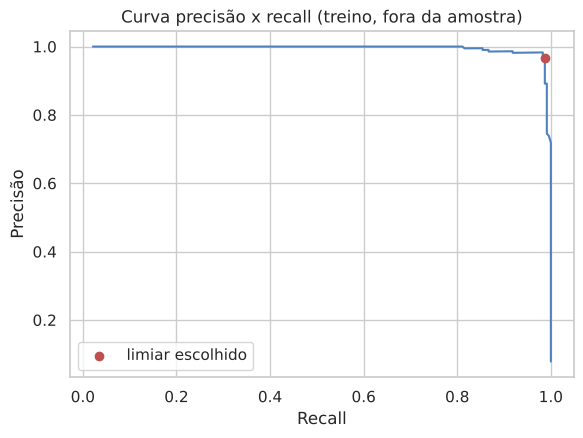

In [16]:
# escolha do limiar de decisão, usando só previsões fora da amostra do treino
prob_oof = cross_val_predict(modelo, X_tr, y_tr, cv=cv, method='predict_proba')[:, 1]
prec, rec, lim = precision_recall_curve(y_tr, prob_oof)
f2 = (5 * prec[:-1] * rec[:-1]) / (4 * prec[:-1] + rec[:-1] + 1e-12)
limiar = float(lim[np.argmax(f2)])
print("Limiar que maximiza o F2 no treino (fora da amostra):", round(limiar, 3))
for t in [0.5, limiar]:
    p = (prob_oof >= t).astype(int)
    print(f"  limiar {t:.3f}: recall {recall_score(y_tr, p):.3f} | precisão {precision_score(y_tr, p):.3f} | F2 {fbeta_score(y_tr, p, beta=2):.3f}")

plt.figure(figsize=(6.5, 4.5))
plt.plot(rec[:-1], prec[:-1], color='#4f81bd')
plt.scatter(recall_score(y_tr, (prob_oof >= limiar)), precision_score(y_tr, (prob_oof >= limiar)), color='#c0504d', zorder=3, label='limiar escolhido')
plt.xlabel('Recall'); plt.ylabel('Precisão'); plt.title('Curva precisão x recall (treino, fora da amostra)')
plt.legend(); plt.show()

# 7. Avaliação no conjunto de teste

Uma única avaliação no teste, com o modelo final e o limiar escolhido no treino. Como o teste tem só 58 casos, calculei também intervalos de confiança por bootstrap.

             recall  precisão     f1     f2
limiar 0,50   0.983     0.983  0.983  0.983
limiar 0.42   0.983     0.983  0.983  0.983

ROC-AUC: 1.0 | PR-AUC: 0.999 | prevalência (PR-AUC de um modelo sem informação): 0.078
Baseline 'sempre sem hipo': acurácia 0.922 | recall 0.0


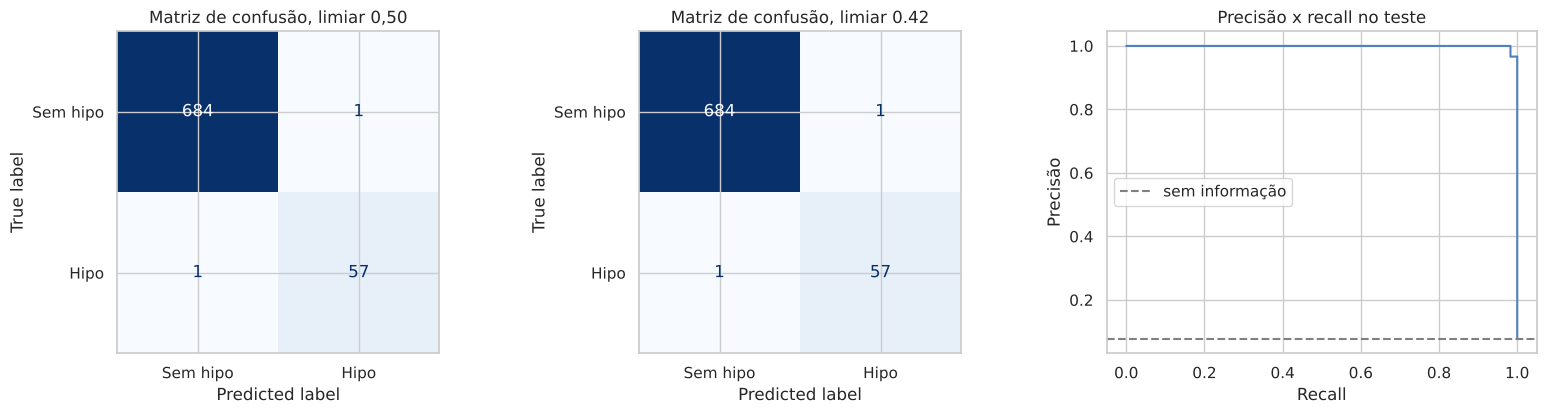


Casos positivos no teste: 58
IC 95% do recall:    [0.943 1.   ]
IC 95% da precisão:  [0.941 1.   ]


In [17]:
# avaliação única no teste (até aqui o teste não foi usado)
prob_te = modelo.predict_proba(X_te)[:, 1]
pred_050 = (prob_te >= 0.5).astype(int)
pred_lim = (prob_te >= limiar).astype(int)

def linha(p):
    return {'recall': recall_score(y_te, p), 'precisão': precision_score(y_te, p), 'f1': f1_score(y_te, p),
            'f2': fbeta_score(y_te, p, beta=2)}
tab = pd.DataFrame({'limiar 0,50': linha(pred_050), f'limiar {limiar:.2f}': linha(pred_lim)}).T
print(tab.round(3).to_string())
print("\nROC-AUC:", round(roc_auc_score(y_te, prob_te), 3), "| PR-AUC:", round(average_precision_score(y_te, prob_te), 3),
      "| prevalência (PR-AUC de um modelo sem informação):", round(y_te.mean(), 3))
base_p = DummyClassifier(strategy='most_frequent').fit(X_tr, y_tr).predict(X_te)
print("Baseline 'sempre sem hipo': acurácia", round((base_p == y_te).mean(), 3), "| recall", recall_score(y_te, base_p))

fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
for a_, p, t in zip(ax[:2], [pred_050, pred_lim], ['limiar 0,50', f'limiar {limiar:.2f}']):
    ConfusionMatrixDisplay(confusion_matrix(y_te, p), display_labels=['Sem hipo', 'Hipo']).plot(ax=a_, colorbar=False, cmap='Blues')
    a_.set_title('Matriz de confusão, ' + t)
pr, rc, _ = precision_recall_curve(y_te, prob_te)
ax[2].plot(rc, pr, color='#4f81bd'); ax[2].axhline(y_te.mean(), ls='--', color='gray', label='sem informação')
ax[2].set_xlabel('Recall'); ax[2].set_ylabel('Precisão'); ax[2].set_title('Precisão x recall no teste'); ax[2].legend()
plt.tight_layout(); plt.show()

# incerteza: só há poucos casos positivos no teste, então bootstrap do recall e da precisão
rng = np.random.default_rng(SEED)
rs, ps = [], []
for _ in range(2000):
    i = rng.integers(0, len(y_te), len(y_te))
    yt, pp = y_te.values[i], pred_lim[i]
    if yt.sum() > 0 and pp.sum() > 0:
        rs.append(recall_score(yt, pp)); ps.append(precision_score(yt, pp))
print("\nCasos positivos no teste:", int(y_te.sum()))
print("IC 95% do recall:   ", np.percentile(rs, [2.5, 97.5]).round(3))
print("IC 95% da precisão: ", np.percentile(ps, [2.5, 97.5]).round(3))

# 8. Importância das variáveis e leitura para o negócio

Usei importância por permutação no teste (quanto a PR-AUC cai quando embaralho uma variável), que não depende de como as árvores usam as variáveis internamente.

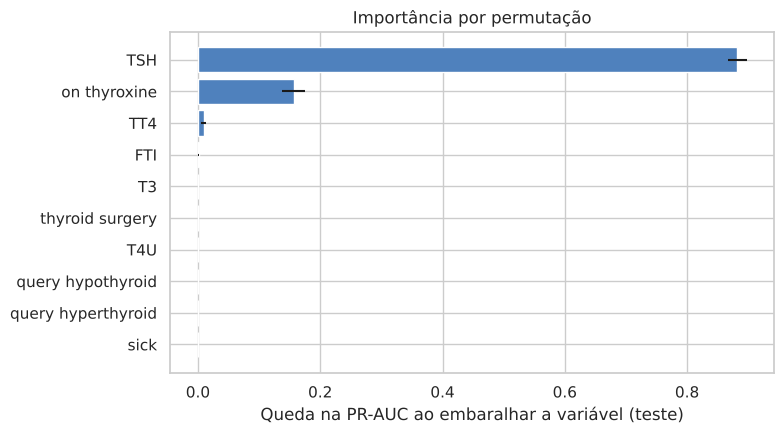

TSH                   0.8820
on thyroxine          0.1564
TT4                   0.0095
FTI                   0.0013
T3                    0.0002
thyroid surgery       0.0001
T4U                   0.0001
query hypothyroid     0.0000
query hyperthyroid    0.0000
sick                  0.0000


In [18]:
# importância por permutação nas colunas originais (mais fácil de ler) usando o pipeline completo
pi = permutation_importance(modelo, X_te, y_te, scoring='average_precision', n_repeats=30, random_state=SEED, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X_te.columns).sort_values(ascending=False)
dp = pd.Series(pi.importances_std, index=X_te.columns).reindex(imp.index)
top = imp.head(10)
plt.figure(figsize=(8, 4.5))
plt.barh(top.index[::-1], top.values[::-1], xerr=dp.head(10).values[::-1], color='#4f81bd')
plt.xlabel('Queda na PR-AUC ao embaralhar a variável (teste)')
plt.title('Importância por permutação')
plt.tight_layout(); plt.show()
print(imp.head(10).round(4).to_string())

In [19]:
# o que a recomendação vira em números, na base de teste
n = len(y_te); pos = int(y_te.sum())
tp = int(((pred_lim == 1) & (y_te.values == 1)).sum()); fp = int(((pred_lim == 1) & (y_te.values == 0)).sum())
fn = pos - tp
print(f"Pacientes no teste: {n} | com hipotireoidismo: {pos}")
print(f"Sinalizados pelo modelo: {tp + fp} ({(tp + fp) / n:.1%} dos pacientes)")
print(f"  casos reais encontrados: {tp} de {pos} | falsos alarmes: {fp} | casos perdidos: {fn}")
print(f"Para cada caso real encontrado, ~{(tp + fp) / max(tp, 1):.1f} pacientes passam pela revisão.")
print(f"Revisar todo mundo teria custado {n} revisões; o modelo pede {tp + fp}.")

# a base tem 7,8% de casos (pacientes encaminhados). Em uma população com menos casos, a precisão cai.
tpr = tp / pos; fpr = fp / (n - pos)
print("\nPrecisão esperada se a prevalência fosse outra (mesmo recall e mesma taxa de falsos alarmes):")
for prev in [0.0784, 0.03, 0.01]:
    print(f"  prevalência {prev:.1%}: precisão ~ {tpr * prev / (tpr * prev + fpr * (1 - prev)):.2f}")

Pacientes no teste: 743 | com hipotireoidismo: 58
Sinalizados pelo modelo: 58 (7.8% dos pacientes)
  casos reais encontrados: 57 de 58 | falsos alarmes: 1 | casos perdidos: 1
Para cada caso real encontrado, ~1.0 pacientes passam pela revisão.
Revisar todo mundo teria custado 743 revisões; o modelo pede 58.

Precisão esperada se a prevalência fosse outra (mesmo recall e mesma taxa de falsos alarmes):
  prevalência 7.8%: precisão ~ 0.98
  prevalência 3.0%: precisão ~ 0.95
  prevalência 1.0%: precisão ~ 0.87


# 9. Checagens finais

Como o resultado ficou muito bom, quis conferir três coisas antes de confiar: se uma regra simples chega perto, se o número se mantém com outras divisões dos dados e quais foram os erros.

In [20]:
# 1) regra simples: uma árvore rasa, ajustada só no treino, chega perto do modelo?
from sklearn.tree import DecisionTreeClassifier, export_text
cols_arv = ['TSH', 'TT4', 'FTI', 'T3', 'T4U', 'age', 'on thyroxine']     # valores originais, para a regra ficar legível
arvore = Pipeline([('imp', SimpleImputer(strategy='median')),
                   ('mod', DecisionTreeClassifier(max_depth=3, class_weight='balanced', random_state=SEED))])
arvore.fit(X_tr[cols_arv], y_tr)
pa = arvore.predict(X_te[cols_arv])
print("Árvore de profundidade 3 no teste: recall", round(recall_score(y_te, pa), 3), "| precisão", round(precision_score(y_te, pa), 3))
print(export_text(arvore.named_steps['mod'], feature_names=cols_arv, decimals=1))

# 2) estabilidade: validação cruzada repetida do modelo final (só treino)
from sklearn.model_selection import RepeatedStratifiedKFold
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
r = cross_validate(modelo, X_tr, y_tr, cv=rcv, scoring={'recall': 'recall', 'precisão': 'precision', 'pr_auc': 'average_precision'}, n_jobs=-1)
for k in ['recall', 'precisão', 'pr_auc']:
    print(f"{k}: {r['test_' + k].mean():.3f} +- {r['test_' + k].std():.3f}")

# 3) os erros do modelo no teste
erros = X_te.assign(real=y_te, prob=prob_te.round(3))[pred_lim != y_te.values]
print("\nErros no teste:")
print(erros[['TSH', 'TT4', 'FTI', 'T3', 'on thyroxine', 'real', 'prob']].to_string())

Árvore de profundidade 3 no teste: recall 1.0 | precisão 0.921
|--- TSH <= 6.0
|   |--- TT4 <= 49.0
|   |   |--- age <= 47.5
|   |   |   |--- class: 1
|   |   |--- age >  47.5
|   |   |   |--- class: 0
|   |--- TT4 >  49.0
|   |   |--- class: 0
|--- TSH >  6.0
|   |--- on thyroxine <= 0.5
|   |   |--- TT4 <= 153.5
|   |   |   |--- class: 1
|   |   |--- TT4 >  153.5
|   |   |   |--- class: 0
|   |--- on thyroxine >  0.5
|   |   |--- FTI <= 62.0
|   |   |   |--- class: 1
|   |   |--- FTI >  62.0
|   |   |   |--- class: 0



recall: 0.979 +- 0.025
precisão: 0.976 +- 0.020
pr_auc: 0.993 +- 0.006

Erros no teste:
       TSH    TT4   FTI   T3  on thyroxine  real   prob
365   24.0   63.0  53.0  NaN             0     1  0.308
3164   6.3  153.0  90.0  2.7             0     0  0.528


# 10. Visualização dos resultados

A figura abaixo resume o que o modelo faz na base de teste: quantas revisões a equipe deixa de fazer e onde estão os poucos erros. Ela é salva em `figures/resultado_final.png`, junto com as métricas em `resultados/metricas_teste.json`.

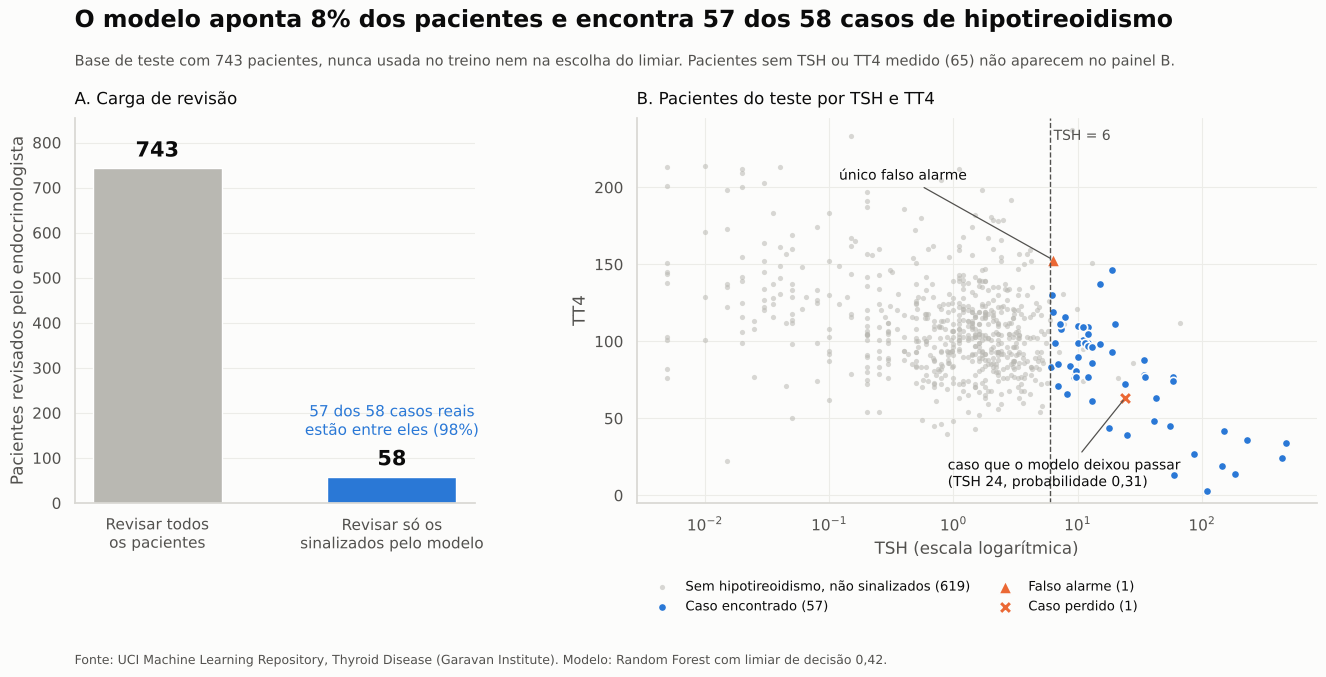

{'pacientes_teste': 743, 'casos_teste': 58, 'sinalizados': 58, 'casos_encontrados': 57, 'falsos_alarmes': 1, 'casos_perdidos': 1, 'limiar': 0.42, 'recall': 0.983, 'precisao': 0.983, 'pr_auc': 0.999}


In [21]:
# visualização final: o que a clínica ganha com o modelo, na base de teste
import os, json
os.makedirs('../figures', exist_ok=True)
os.makedirs('../resultados', exist_ok=True)

AZUL, LARANJA, CINZA = '#2a78d6', '#eb6834', '#b9b8b2'
TXT, TXT2, FUNDO = '#0b0b0b', '#52514e', '#fcfcfb'

real = y_te.values
n = len(real); pos = int(real.sum())
tp = int(((pred_lim == 1) & (real == 1)).sum())
fp = int(((pred_lim == 1) & (real == 0)).sum())
fn = int(((pred_lim == 0) & (real == 1)).sum())
sinalizados = tp + fp

fig = plt.figure(figsize=(13.5, 7.0), facecolor=FUNDO)
gs = fig.add_gridspec(1, 2, width_ratios=[1, 1.7], wspace=0.30, left=0.06, right=0.98, top=0.80, bottom=0.25)

# painel A: quantas revisões a clínica faz
ax = fig.add_subplot(gs[0]); ax.set_facecolor(FUNDO)
rotulos = ['Revisar todos\nos pacientes', 'Revisar só os\nsinalizados pelo modelo']
valores = [n, sinalizados]
barras = ax.bar(rotulos, valores, color=[CINZA, AZUL], width=0.55)
for b, v in zip(barras, valores):
    ax.text(b.get_x() + b.get_width() / 2, v + n * 0.02, f'{v}', ha='center', va='bottom', fontsize=15, color=TXT, fontweight='bold')
ax.set_ylim(0, n * 1.15)
ax.set_ylabel('Pacientes revisados pelo endocrinologista', color=TXT2)
ax.set_title('A. Carga de revisão', loc='left', color=TXT, fontsize=12, pad=10)
ax.text(1, sinalizados + n * 0.11, f'{tp} dos {pos} casos reais\nestão entre eles ({tp / pos:.0%})', ha='center', va='bottom', fontsize=11, color=AZUL)
for s in ['top', 'right']: ax.spines[s].set_visible(False)
ax.spines['left'].set_color('#d9d8d3'); ax.spines['bottom'].set_color('#d9d8d3')
ax.tick_params(colors=TXT2); ax.grid(False); ax.grid(axis='y', color='#ececE8', linewidth=0.8); ax.set_axisbelow(True)

# painel B: onde os pacientes ficam no espaço TSH x TT4
ax = fig.add_subplot(gs[1]); ax.set_facecolor(FUNDO)
d = X_te[['TSH', 'TT4']].assign(real=real, pred=pred_lim, prob=prob_te)
ok = d.dropna(subset=['TSH', 'TT4'])
neg = ok[(ok.real == 0) & (ok.pred == 0)]
ach = ok[(ok.real == 1) & (ok.pred == 1)]
per = ok[(ok.real == 1) & (ok.pred == 0)]
fal = ok[(ok.real == 0) & (ok.pred == 1)]
ax.scatter(neg['TSH'], neg['TT4'], s=14, color=CINZA, alpha=0.55, linewidths=0, label=f'Sem hipotireoidismo, não sinalizados ({len(neg)})')
ax.scatter(ach['TSH'], ach['TT4'], s=36, color=AZUL, edgecolors=FUNDO, linewidths=1.2, label=f'Caso encontrado ({len(ach)})')
ax.scatter(fal['TSH'], fal['TT4'], s=90, color=LARANJA, marker='^', edgecolors=FUNDO, linewidths=1.2, label=f'Falso alarme ({len(fal)})')
ax.scatter(per['TSH'], per['TT4'], s=90, color=LARANJA, marker='X', edgecolors=FUNDO, linewidths=1.2, label=f'Caso perdido ({len(per)})')
ax.set_xscale('log'); ax.set_ylim(-5, 245); ax.axvline(6, ls='--', lw=1, color=TXT2)
ax.text(6.4, ax.get_ylim()[1] * 0.97, 'TSH = 6', color=TXT2, fontsize=10, va='top')
for _, r in per.iterrows():
    ax.annotate(f"caso que o modelo deixou passar\n(TSH {r['TSH']:.0f}, probabilidade {r['prob']:.2f})".replace('.', ','), (r['TSH'], r['TT4']), xytext=(0.9, 6),
                fontsize=10, color=TXT, arrowprops=dict(arrowstyle='-', color=TXT2, lw=0.9))
for _, r in fal.iterrows():
    ax.annotate('único falso alarme', (r['TSH'], r['TT4']), xytext=(0.12, 205),
                fontsize=10, color=TXT, arrowprops=dict(arrowstyle='-', color=TXT2, lw=0.9))
ax.set_xlabel('TSH (escala logarítmica)', color=TXT2); ax.set_ylabel('TT4', color=TXT2)
ax.set_title('B. Pacientes do teste por TSH e TT4', loc='left', color=TXT, fontsize=12, pad=10)
ax.legend(loc='upper left', frameon=False, fontsize=9.5, labelcolor=TXT, bbox_to_anchor=(0.0, -0.17), ncol=2, columnspacing=1.6)
for s in ['top', 'right']: ax.spines[s].set_visible(False)
ax.spines['left'].set_color('#d9d8d3'); ax.spines['bottom'].set_color('#d9d8d3')
ax.tick_params(colors=TXT2); ax.grid(color='#ececE8', linewidth=0.8); ax.set_axisbelow(True)

fig.text(0.06, 0.93, f'O modelo aponta {sinalizados / n:.0%} dos pacientes e encontra {tp} dos {pos} casos de hipotireoidismo',
         fontsize=17, color=TXT, fontweight='bold', ha='left')
fig.text(0.06, 0.875, f'Base de teste com {n} pacientes, nunca usada no treino nem na escolha do limiar. '
         f'Pacientes sem TSH ou TT4 medido ({len(d) - len(ok)}) não aparecem no painel B.',
         fontsize=10.5, color=TXT2, ha='left')
fig.text(0.06, 0.02, 'Fonte: UCI Machine Learning Repository, Thyroid Disease (Garavan Institute). Modelo: Random Forest com limiar de decisão 0,42.',
         fontsize=9, color=TXT2, ha='left')
fig.savefig('../figures/resultado_final.png', dpi=160, facecolor=FUNDO)
plt.show()

metricas = {'pacientes_teste': n, 'casos_teste': pos, 'sinalizados': sinalizados, 'casos_encontrados': tp,
            'falsos_alarmes': fp, 'casos_perdidos': fn, 'limiar': round(limiar, 3),
            'recall': round(float(recall_score(y_te, pred_lim)), 3), 'precisao': round(float(precision_score(y_te, pred_lim)), 3),
            'pr_auc': round(float(average_precision_score(y_te, prob_te)), 3)}
json.dump(metricas, open('../resultados/metricas_teste.json', 'w'), ensure_ascii=False, indent=2)
print(metricas)

# 11. Conclusões e recomendação

**O que o modelo entrega.** Na base de teste (743 pacientes, 58 casos) o modelo sinalizou 58 pacientes, encontrou 57 dos 58 casos e teve 1 falso alarme. Recall e precisão de 0,98, PR-AUC de 0,999. Na validação cruzada repetida (3x5) o resultado foi parecido, recall 0,979 e precisão 0,976, com desvio de cerca de 0,02. O baseline que não encontra ninguém tem acurácia de 92%, então só a acurácia não serviria para comparar.

**O que isso significa de verdade.** O resultado é bom demais para ser lido como "o modelo diagnostica hipotireoidismo". Uma árvore de profundidade 3, que se lê em poucas linhas (TSH acima de 6, uso de tiroxina, TT4 e FTI baixos), já chega a recall 1,0 no teste, com precisão menor (0,92). Ou seja, o rótulo parece vir de uma regra aplicada aos mesmos exames que dei ao modelo. O que o modelo aprendeu foi essa regra, e por isso o TSH (0,88 de importância) e o uso de tiroxina (0,16) dominam. Sem um diagnóstico independente dos exames não consigo afirmar que ele generaliza para a prática clínica.

**Recomendação.**

1. Usar o modelo como segunda leitura automática dos resultados de laboratório: ele aponta cerca de 8% dos pacientes para revisão do endocrinologista e deixa de fora os outros 92%, em vez de revisar os 743. O ganho é consistência e tempo, não descoberta de casos que um médico não veria.
2. Tratar à parte quem já usa tiroxina: com TSH alto eles aparecem como casos só 14% das vezes, e a conduta ali é ajuste de dose, não diagnóstico novo.
3. Para os pacientes sem TSH medido (309 na base, nenhum caso), o modelo não tem o que avaliar. Vale pedir o TSH, principalmente quando o médico já marcou suspeita de hipotireoidismo, que na base tem taxa de 16,7%.
4. Antes de qualquer uso real, validar com dados de outra clínica e com um diagnóstico que não dependa desses exames. A prevalência de 7,8% é de pacientes encaminhados: numa população com 1% de casos a precisão estimada cairia para perto de 0,87 (cálculo na seção 8).

**Limitações.** Poucos casos (58 no teste, intervalo de confiança do recall entre 0,94 e 1,00), base antiga e de uma única fonte (o UCI avisa que ela pode ter sido corrompida desde a doação), e os dois erros do teste são casos de fronteira. Um deles é um paciente com TSH de 24 e TT4 baixo que o modelo deixou passar (probabilidade 0,31), o que me incomoda mais do que o falso alarme, e não consegui explicar com certeza por que aconteceu.